In [1]:
import logging
import os
import torch

logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s - %(message)s', datefmt='%H:%M:%S')

In [51]:
if os.name == "nt":
    bart_base_path = r"D:\data\trained_net\transformers\bart-base"
    bart_tiny_path = r"D:\data\trained_net\transformers\tinier_bart"
else:
    bart_base_path = "/home/randool/Dataset/transformers/bart-base"
    bart_tiny_path = "/home/randool/Dataset/transformers/tinier-bart"

dataset = "librispeech"
lattice_path = f"debug/{dataset}/pruned.lat.[1-3].txt"
text_path = f"debug/{dataset}/text"

In [52]:
def test_model_param_match(model_path=bart_tiny_path):
    from models.lattice_bart import LatticeBart
    model = LatticeBart.from_bart(model_path)
    return model


def get_tokenizer(model_path=bart_tiny_path):
    from transformers import BartTokenizer
    return BartTokenizer.from_pretrained(model_path)


def test_batch_data(model_path=bart_tiny_path, batch_size=4, min_nodes=10, max_nodes=100):
    from transformers import BartTokenizer
    from utils.dataset import LatticeDataset
    from torch.utils.data.dataloader import DataLoader

    lat2text = LatticeDataset(lattice_path, text_path, min_nodes=min_nodes, max_nodes=max_nodes)
    lat2text.sort_by_length()

    tokenizer = get_tokenizer(model_path)
    dataloader = DataLoader(lat2text, batch_size=batch_size, collate_fn=lat2text.partial_collate_fn(tokenizer))

    return dataloader

# Lattice length distribution

In [53]:
def display_length_distribution():
    import matplotlib.pyplot as plt
    from utils.dataset import LatticeDataset

    # lattice_path = f"debug/{dataset}/pruned.lat.[1-5].txt"
    lat2text = LatticeDataset(lattice_path, text_path)
    len_node = []
    len_text = []
    for _id, G, text in lat2text.pairs:
        n_node = len(G)
        n_word = len(text.split())
        len_node.append(n_node)
        len_text.append(n_word)
        if n_node < n_word:
            print(f"{_id}, #node={n_node}, #text={n_word}")
    plt.scatter(len_text, len_node)
    plt.xlabel("#word")
    plt.ylabel("#node")
    plt.tight_layout()
    plt.show()

15:42:28 INFO - Load lattice from debug/librispeech/pruned.lat.1.txt. Lattice count: 144.
15:42:28 INFO - Load lattice from debug/librispeech/pruned.lat.2.txt. Lattice count: 268.
15:42:28 INFO - Load lattice from debug/librispeech/pruned.lat.3.txt. Lattice count: 407.
15:42:29 INFO - LatticeDataset: 407 pairs


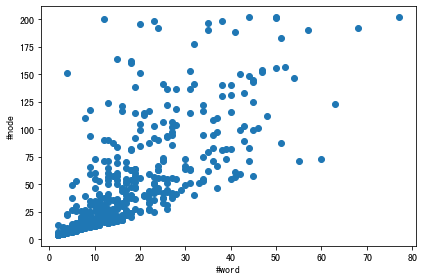

In [54]:
display_length_distribution()

# Lattice Attention

## Train tiny bart

In [55]:
def test_model_train(model, dataloader, epoch=20):
    from transformers import AdamW

    optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    for e in range(epoch):
        for i, inputs in enumerate(dataloader, start=1):
            outputs = model.forward(**inputs)
            loss = outputs["loss"]
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1)
            if i % 20 == 0:
                print(f"{i}/{len(dataloader)}\tloss={loss.item():.2e}")
            optimizer.step()
            optimizer.zero_grad()

In [62]:
tokenizer = get_tokenizer(bart_base_path)

In [56]:
model = test_model_param_match(bart_base_path)
model

LatticeBart(
  (model): LatticeBartBase(
    (shared): Embedding(50265, 768, padding_idx=1)
    (encoder): LatticeEncoder(
      (embed_tokens): Embedding(50265, 768, padding_idx=1)
      (positional_embed): Embedding(100, 768)
      (marginal_proj): Linear(in_features=1, out_features=768, bias=True)
      (lattice_layer): LatticeEncoderLayer(
        (lattice_self_attn): LatticeSelfAttention(
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (out_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (self_attn_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (final_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine

In [60]:
dataloader = test_batch_data(min_nodes=10, max_nodes=100)

15:48:46 INFO - Load lattice from debug/librispeech/pruned.lat.1.txt. Lattice count: 144.
15:48:46 INFO - Load lattice from debug/librispeech/pruned.lat.2.txt. Lattice count: 268.
15:48:46 INFO - Load lattice from debug/librispeech/pruned.lat.3.txt. Lattice count: 407.
15:48:46 INFO - LatticeDataset: 103 pairs (25.31%) filtered
15:48:46 INFO - LatticeDataset: 304 pairs


In [61]:
test_model_train(model, dataloader, 2)

20/76	loss=6.68e+00
40/76	loss=7.19e+00
60/76	loss=6.86e+00
20/76	loss=6.31e+00
40/76	loss=6.69e+00
60/76	loss=6.21e+00


## Forward with attention

In [63]:
collate_fn = dataloader.dataset.partial_collate_fn(tokenizer)

16:09:02 INFO - Load lattice from debug/librispeech/pruned.lat.1.txt. Lattice count: 144.
16:09:02 INFO - Load lattice from debug/librispeech/pruned.lat.2.txt. Lattice count: 268.
16:09:02 INFO - Load lattice from debug/librispeech/pruned.lat.3.txt. Lattice count: 407.
16:09:02 INFO - LatticeDataset: 103 pairs (25.31%) filtered
16:09:02 INFO - LatticeDataset: 304 pairs


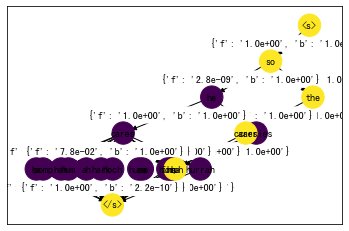

In [70]:
from utils.graph_visual import display_line_graph
from utils.dataset import scoring_line_graph

lat_id = '174-50561-0018'
dataloader = test_batch_data(min_nodes=10, max_nodes=100)

for pair in dataloader.dataset.pairs:
    if pair[0] == example[0]:
        display_line_graph(scoring_line_graph(pair[1]))
        break

In [65]:
example = dataloader.dataset[0]  # id, lat_info, text
print(example)

inputs = collate_fn([example])
# print(inputs)

('1988-24833-0010', LAT_INFO(words='<s> so he cares ah hark pa hump hurrah ha hah hum hoch pomp for humph carries ha the cares ha </s>', marginal=[1.0, 1.0, 2.828837455416816e-09, 2.828837455416816e-09, 2.210296768451307e-10, 2.4584028321801146e-11, 1.4722795057064386e-11, 3.213343178748466e-11, 1.4079178120035026e-11, 1.3686730555611476e-09, 4.198015375106845e-11, 2.0915635239511388e-11, 6.649867813955611e-12, 8.199817384797085e-11, 9.9434773240138e-10, 7.723726670266727e-12, 4.6229643557537514e-66, 4.6229643557537514e-66, 0.9999999971711626, 0.9999999971711626, 0.9999999971711626, 1.0], min_depth=[0, 1, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 4, 2, 3, 4, 5], max_depth=[0, 1, 2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 4, 2, 3, 4, 5], fb=tensor([[0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
  

In [66]:
encoder_text = example[1].words.split()
decoder_text = ["<s>"] + example[2].split()
print(encoder_text)
print(decoder_text)

['<s>', 'so', 'he', 'cares', 'ah', 'hark', 'pa', 'hump', 'hurrah', 'ha', 'hah', 'hum', 'hoch', 'pomp', 'for', 'humph', 'carries', 'ha', 'the', 'cares', 'ha', '</s>']
['<s>', 'so', 'he', 'cares', 'huh']


In [67]:
import torch

model.eval()
with torch.no_grad():
    outputs = model.forward(**inputs, output_attentions=True)
outputs.keys()

odict_keys(['loss', 'logits', 'past_key_values', 'decoder_attentions', 'cross_attentions', 'encoder_last_hidden_state', 'encoder_attentions'])

In [68]:
from bertviz import head_view, model_view

In [69]:
head_view(
    encoder_attention=outputs.encoder_attentions, 
    decoder_attention=outputs.decoder_attentions,
    cross_attention=outputs.cross_attentions,
    encoder_tokens=encoder_text,
    decoder_tokens=decoder_text
)

<IPython.core.display.Javascript object>